In [1]:
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, BatchNormalization, Dropout
import matplotlib.pyplot as plt
import cv2

In [2]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    directory=r'B:\Jupyter Notebook\Github Projects\Dog vs cat CNN\Data\train',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256, 256)
)

Found 20000 files belonging to 2 classes.


In [3]:
# Load the validation dataset
validation_ds = keras.utils.image_dataset_from_directory(
    directory='B:\Jupyter Notebook\Github Projects\Dog vs cat CNN\Data/test',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256, 256)
)

Found 5000 files belonging to 2 classes.


<>:3: SyntaxWarning: "\J" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\J"? A raw string is also an option.
<>:3: SyntaxWarning: "\J" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\J"? A raw string is also an option.
C:\Users\Rihan\AppData\Local\Temp\ipykernel_28528\1823737541.py:3: SyntaxWarning: "\J" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\J"? A raw string is also an option.
  directory='B:\Jupyter Notebook\Github Projects\Dog vs cat CNN\Data/test',


In [4]:
# 3. DATA PREPROCESSING (NORMALIZATION)
# Normalize pixel values from [0, 255] to [0, 1]

def process(image, label):
    image = tf.cast(image / 255., tf.float32)
    return image, label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

In [5]:
# 4. CNN MODEL ARCHITECTURE

model = Sequential()

# 1st Convolutional Block
model.add(Conv2D(32, kernel_size=(3, 3), padding='valid', activation='relu', input_shape=(256, 256, 3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='valid'))

# 2nd Convolutional Block
model.add(Conv2D(64, kernel_size=(3, 3), padding='valid', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='valid'))

# 3rd Convolutional Block
model.add(Conv2D(128, kernel_size=(3, 3), padding='valid', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='valid'))

# Flattening and Fully Connected Layers
model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.1))

model.add(Dense(64, activation='relu'))
model.add(Dropout(0.1))

# Output Layer for Binary Classification
model.add(Dense(1, activation='sigmoid'))

c:\Users\Rihan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [7]:
# 5. MODEL COMPILATION & TRAINING

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Execute training across 10 epochs
history = model.fit(train_ds, epochs=10, validation_data=validation_ds)

Epoch 1/10


c:\Users\Rihan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


625/625 ━━━━━━━━━━━━━━━━━━━━ 1148s 2s/step - accuracy: 0.5597 - loss: 1.3630 - val_accuracy: 0.6110 - val_loss: 0.6492
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3372s 5s/step - accuracy: 0.6647 - loss: 0.6134 - val_accuracy: 0.6538 - val_loss: 0.6611
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 1025s 2s/step - accuracy: 0.7271 - loss: 0.5282 - val_accuracy: 0.6706 - val_loss: 0.6249
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 1669s 3s/step - accuracy: 0.7645 - loss: 0.4754 - val_accuracy: 0.7058 - val_loss: 0.6704
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 1025s 2s/step - accuracy: 0.7969 - loss: 0.4276 - val_accuracy: 0.7980 - val_loss: 0.4840
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 1024s 2s/step - accuracy: 0.8153 - loss: 0.3836 - val_accuracy: 0.6702 - val_loss: 0.7080
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 1024s 2s/step - accuracy: 0.8447 - loss: 0.3391 - val_accuracy: 0.7944 - val_loss: 0.4660
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 1275s 2s/step - accuracy: 0.8642 - loss: 0.2831 - val_accurac

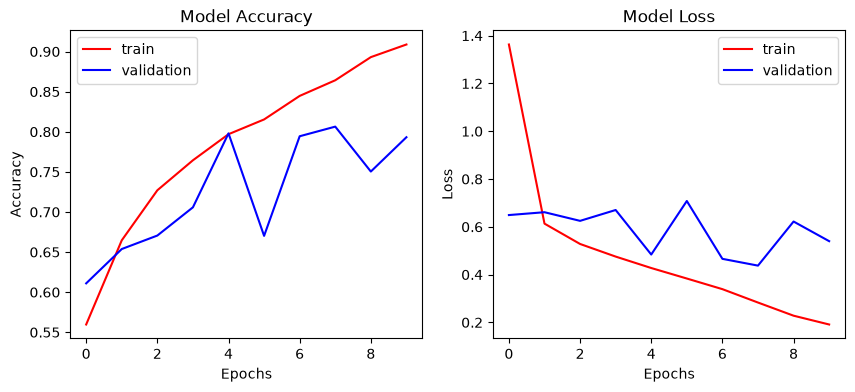

In [8]:
# 6. EVALUATION (LOSS & ACCURACY PLOTS)

# Plot Accuracy
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color='blue', label='validation')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color='blue', label='validation')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [11]:
from pathlib import Path

MODEL_DIR = Path(
    r"B:\Jupyter Notebook\Github Projects\Dog vs cat CNN\Models"
)

model_path = MODEL_DIR / "dog_cat_cnn_v1.keras"

# Save your trained CNN
model.save(model_path)

print("Model saved successfully!")
print("Location:", model_path)
print(f"Size: {model_path.stat().st_size / (1024**2):.2f} MB")

Model saved successfully!
Location: B:\Jupyter Notebook\Github Projects\Dog vs cat CNN\Models\dog_cat_cnn_v1.keras
Size: 169.99 MB


In [18]:
loaded_model = tf.keras.models.load_model(
    MODEL_DIR / "dog_cat_cnn_v1.keras"
)

loaded_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,543,685 (169.92 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

 Optimizer params: 29,695,492 (113.28 MB)

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)

In [14]:
test_path = Path(
    r"B:\Jupyter Notebook\Github Projects\Dog vs cat CNN\Data\test"
)

# Match class indices assigned by image_dataset_from_directory
class_names = sorted(
    folder.name for folder in test_path.iterdir()
    if folder.is_dir()
)

print("Class names:", class_names)

# Collect true labels and predicted probabilities
y_true = []
y_prob = []

for images, labels in validation_ds:
    probabilities = model.predict(images, verbose=0).ravel()

    y_true.extend(labels.numpy().astype(int))
    y_prob.extend(probabilities)

y_true = np.array(y_true)
y_prob = np.array(y_prob)

y_pred = (y_prob >= 0.5).astype(int)

print("Total evaluated images:", len(y_true))

Class names: ['cats', 'dogs']
Total evaluated images: 5000


In [15]:
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

Accuracy: 0.7932

Classification Report:

              precision    recall  f1-score   support

        cats     0.7545    0.8692    0.8078      2500
        dogs     0.8458    0.7172    0.7762      2500

    accuracy                         0.7932      5000
   macro avg     0.8001    0.7932    0.7920      5000
weighted avg     0.8001    0.7932    0.7920      5000



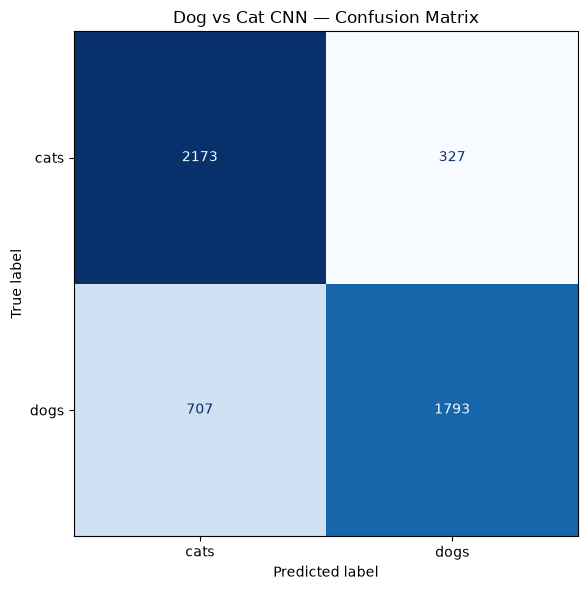

Confusion matrix saved to: B:\Jupyter Notebook\Github Projects\Dog vs cat CNN\Results\confusion_matrix.png


In [ ]:
PROJECT_DIR = Path(
    r"B:\Jupyter Notebook\Github Projects\Dog vs cat CNN"
)

RESULTS_DIR = PROJECT_DIR / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(7, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Dog vs Cat CNN — Confusion Matrix")
plt.tight_layout()

fig.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Confusion matrix saved to:", RESULTS_DIR / "confusion_matrix.png")

In [17]:
#GradCam

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

# Project paths
PROJECT_DIR = Path(
    r"B:\Jupyter Notebook\Github Projects\Dog vs cat CNN"
)

TEST_DIR = PROJECT_DIR / "Data" / "test"
GRADCAM_DIR = PROJECT_DIR / "Results" / "gradcam"
GRADCAM_DIR.mkdir(parents=True, exist_ok=True)

# Find class folders and an image
class_names = sorted(
    folder.name for folder in TEST_DIR.iterdir()
    if folder.is_dir()
)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_paths = [
    path for path in TEST_DIR.rglob("*")
    if path.suffix.lower() in image_extensions
]

if not image_paths:
    raise FileNotFoundError(
        f"No supported images found in {TEST_DIR}"
    )

image_path = image_paths[0]

print("Classes:", class_names)
print("Selected image:", image_path)

# Identify the last convolutional layer
last_conv_layer = next(
    layer for layer in reversed(model.layers)
    if isinstance(layer, tf.keras.layers.Conv2D)
)

print("Grad-CAM layer:", last_conv_layer.name)

# Build a model that returns convolutional features
# and the final prediction
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[last_conv_layer.output, model.output]
)

Classes: ['cats', 'dogs']
Selected image: B:\Jupyter Notebook\Github Projects\Dog vs cat CNN\Data\test\cats\cat.10.jpg
Grad-CAM layer: conv2d_2


AttributeError: The layer sequential has never been called and thus has no defined output.